REDDIT MENTAL HEALTH Prediction 

A multi-class classification problem

Column names: 'Text', 'Title', 'Target'

Input

Raw text

Output

Target

0 = Stress

1 = Depression

2 = Bipolar disorder

3 = Personality disorder

4 = Anxiety

1️⃣ Importing Libraries

In [3]:
import re
import pandas as pd
import numpy as numpy
import nltk
from nltk.corpus import stopwords
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
import joblib

nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\hp\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

2️⃣ Load Dataset

In [5]:
df = pd.read_csv("data_to_be_cleansed.csv")

print("Dataset loaded successfully")
print(f"Total samples: {len(df)}\n")
df.head(10)
df.columns

Dataset loaded successfully
Total samples: 5957



Index(['Unnamed: 0', 'text', 'title', 'target'], dtype='object')

3️⃣ Clean Text Function

In [8]:
def clean_text(text):
    if not isinstance(text, str):
        return ""
    text = re.sub(r'[^a-zA-Z\s]', '', text)   # remove non-letters
    text = text.lower()                       # lowercase
    stop_words = set(stopwords.words('english'))
    text = ' '.join(word for word in text.split() if word not in stop_words)
    return text


4️⃣ Clean the Dataset

In [9]:
# Drop missing rows
df = df.dropna(subset=['text', 'target'])

# Combine title + text into one field (helps model context)
df['combined_text'] = df['title'].astype(str) + " " + df['text'].astype(str)

# Apply cleaning
df['clean_text'] = df['combined_text'].apply(clean_text)

print(" Cleaned text examples:")
print(df[['clean_text', 'target']].head())




 Cleaned text examples:
                                          clean_text  target
0  regular checkin post information rules wikis w...       1
1  mostbroken leastunderstood rules helpers may i...       1
2  havent touched even hugged long cant even reme...       1
3  depressed embarrassing im ashamed everyone eve...       1
4  im desperate friend feel loved someone really ...       1


5️⃣ Balanced Sample (100 rows total)

In [10]:
# Group by label and sample equally (20 each for 5 classes)
sample_data = df.groupby('target').apply(
    lambda x: x.sample(min(len(x), 20), random_state=42)
).reset_index(drop=True)

print(f"Balanced sample size: {len(sample_data)}")
print(sample_data['target'].value_counts())
sample_data.to_csv("balanced_sample.csv", index=False)


Balanced sample size: 100
target
0    20
1    20
2    20
3    20
4    20
Name: count, dtype: int64


C:\Users\hp\AppData\Local\Temp\ipykernel_16064\3310945954.py:2: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sample_data = df.groupby('target').apply(


6️⃣ Train/Test Split 

In [11]:
X = sample_data['clean_text']
y=sample_data['target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.2, random_state=42, stratify=y)

print(f"Training samples: {len(X_train)}")
print(f"Testing samples: {len(X_test)}")

Training samples: 80
Testing samples: 20


7️⃣ TF-IDF Vectorization


In [17]:
vectorizer = TfidfVectorizer(max_features= 5000, ngram_range=(1, 2), stop_words= 'english')
vectorizer.fit(X_train)

X_train_tfidf = vectorizer.transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)


8️⃣ Model training

In [18]:
model= MultinomialNB()
model.fit(X_train_tfidf, y_train)

# save model and vectorizer
joblib.dump(model, 'mental_health_model.pkl')
joblib.dump(vectorizer, 'tfidf_vectorizer.pkl')

print("Model trained and saved")

Model trained and saved


9️⃣ Model Evaluation

In [19]:
y_pred = model.predict(X_test_tfidf)

# metrics
accuracy = accuracy_score(y_test, y_pred)
precision  = precision_score(y_test, y_pred, average= 'weighted')
recall = recall_score(y_test, y_pred, average='weighted')
f1 = f1_score(y_test, y_pred, average='weighted')

print(f"\nAccuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))


Accuracy: 0.6000
Precision: 0.7867
Recall: 0.6000
F1 Score: 0.6104

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.75      0.86         4
           1       0.33      0.75      0.46         4
           2       1.00      0.25      0.40         4
           3       1.00      0.50      0.67         4
           4       0.60      0.75      0.67         4

    accuracy                           0.60        20
   macro avg       0.79      0.60      0.61        20
weighted avg       0.79      0.60      0.61        20



🔟 Confusion Matrix 

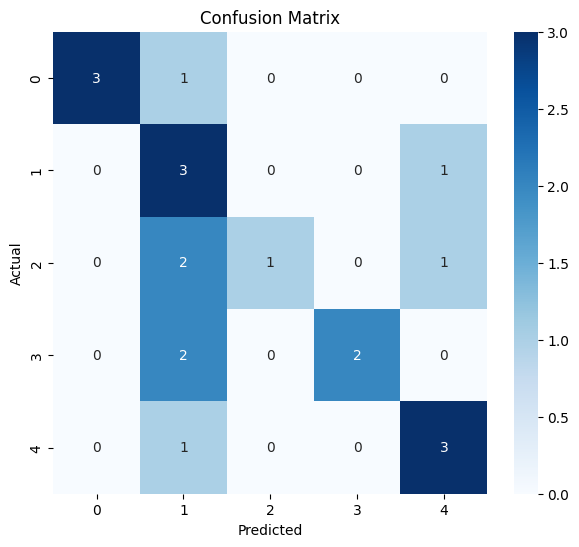

In [20]:
import seaborn as sns
conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7,6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()